In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

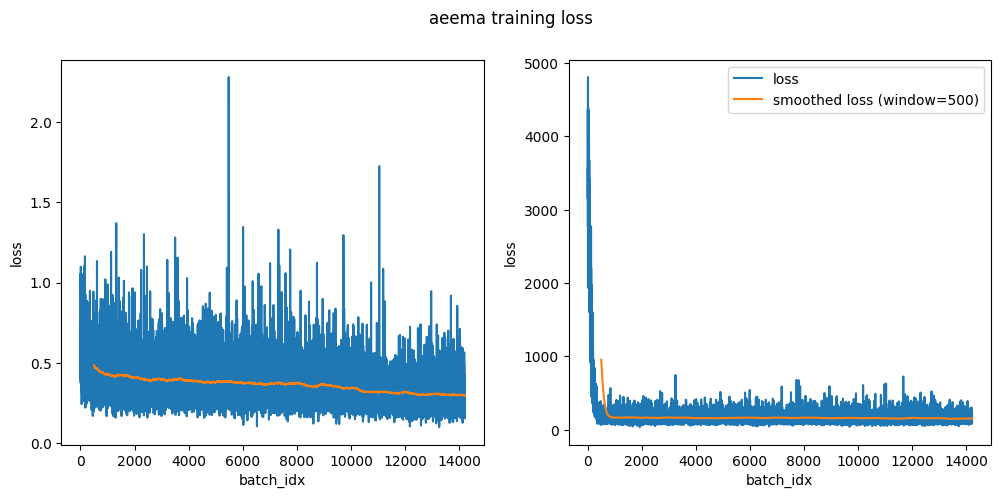

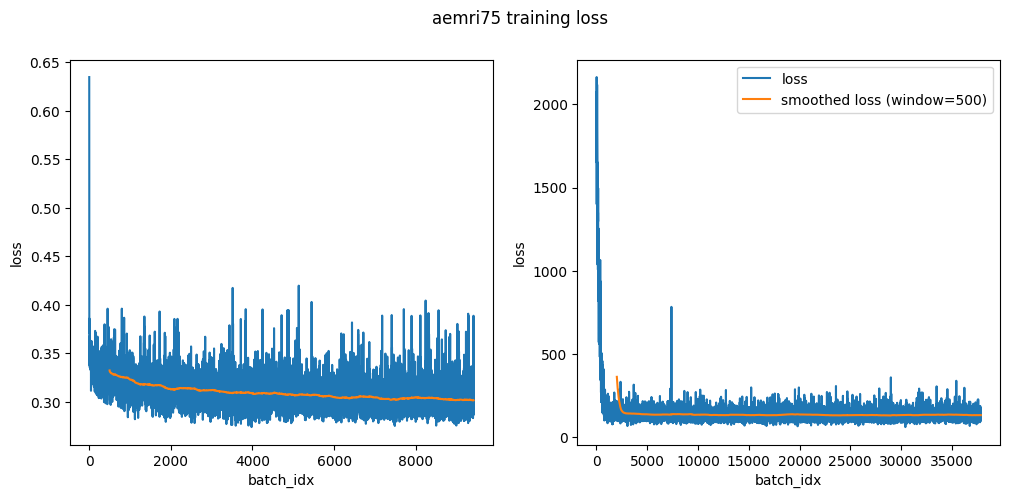

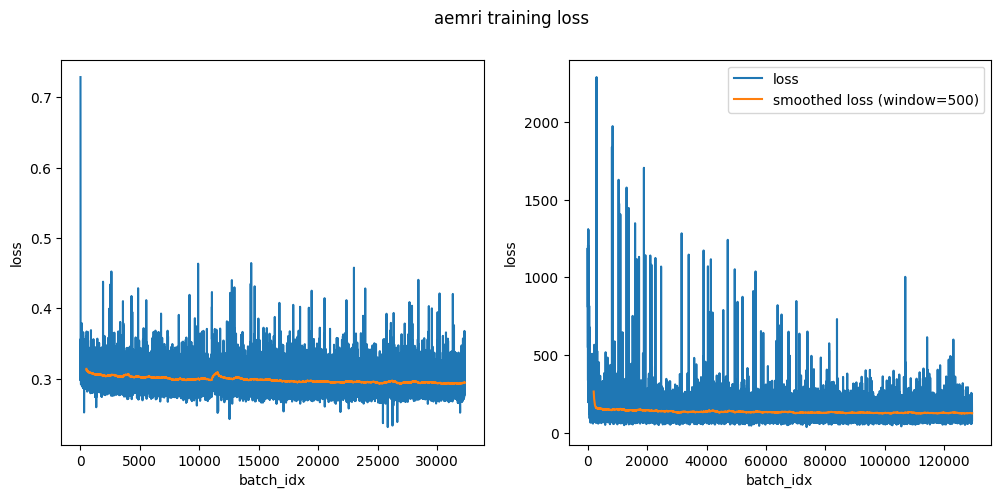

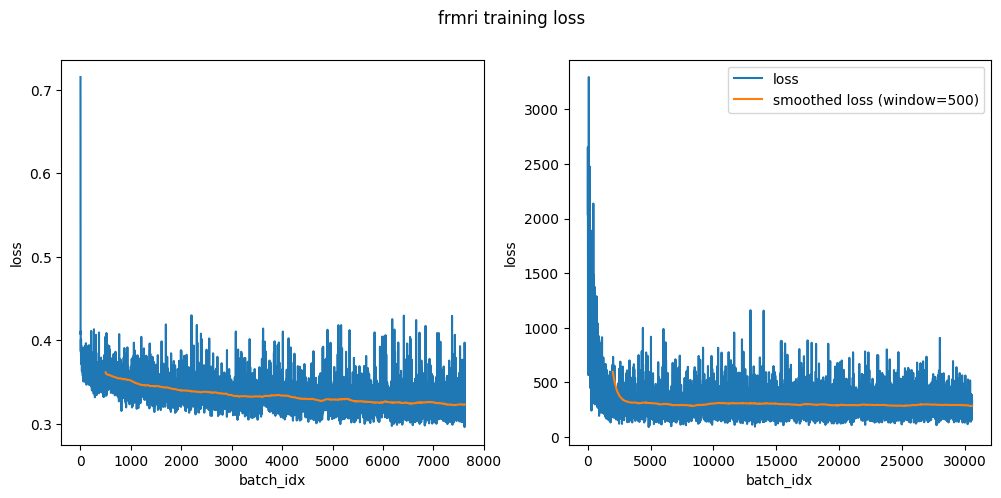

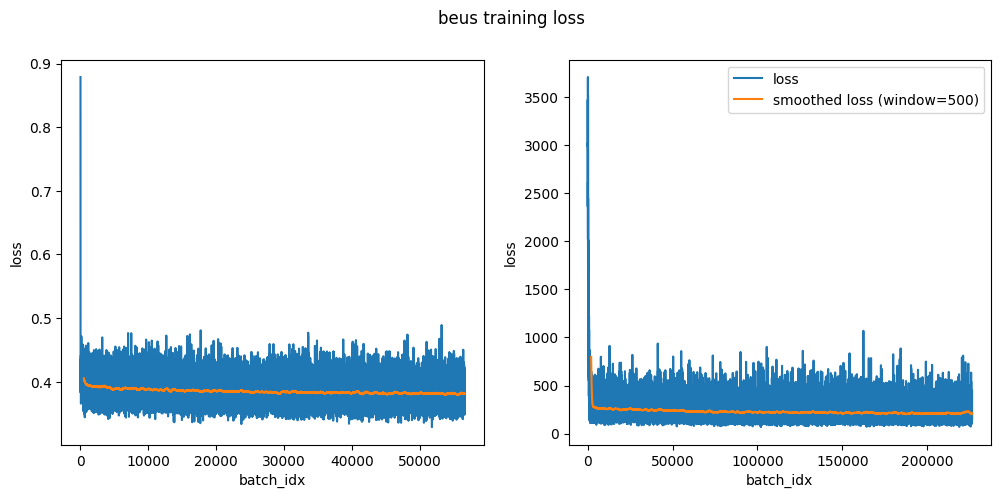

In [4]:
window_size = 500
for dataset_name in ["aeema", "aemri75", "aemri", "frmri", "beus"]:
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    df = pd.read_csv(f"{dataset_name}/art_model_training_log.csv")
    sns.lineplot(data=df, x="batch_idx", y="loss", ax=axs[0])
    df["smoothed_loss"] = df["loss"].rolling(window=window_size).mean()
    sns.lineplot(data=df, x="batch_idx", y="smoothed_loss", ax=axs[0])

    df = pd.read_csv(f"{dataset_name}/ac_model_training_log.csv")
    sns.lineplot(data=df, x="batch_idx", y="loss", ax=axs[1], label="loss")
    df["smoothed_loss"] = df["loss"].rolling(window=window_size).mean()
    sns.lineplot(data=df, x="batch_idx", y="smoothed_loss", ax=axs[1], label=f"smoothed loss (window={window_size})")
    fig.suptitle(f"{dataset_name} training loss")
    plt.show()